# 6 · Surface pH in a boundary layer during GITT pulses

In aqueous batteries the electrode reaction often consumes (or produces) protons. During a galvanostatic intermittent titration (GITT) experiment, the current is switched on and off, and the **pH at the electrode surface** departs from the bulk pH and relaxes back. How far it moves, and how fast it recovers, is set by diffusion across the thin electrolyte layer next to the surface.

This notebook solves that problem with `bandsolver`'s built-in integrator and checks it against the exact solution:

1. the model: H⁺ diffusion across a layer of thickness $\delta$, with a switched surface flux;
2. the exact solution (a Fourier series, plus superposition for pulse trains) and its two limits;
3. a finite-volume discretization, integrated with `bs.integrate` one pulse segment at a time;
4. validation: second-order convergence in space, convergence in the time tolerance, and both limits;
5. the physics: why a 1 µm layer follows the current instantly while a 100 µm layer relaxes during the rests.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import bandsolver as bs

# Plot style shared with the other notebooks.
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
RAMP = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281"]   # light -> dark
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "lines.markersize": 6, "legend.frameon": False,
    "figure.dpi": 110, "font.size": 10, "axes.titlesize": 11,
})

## 1. The model

Let $c(x,t)$ be the proton concentration in a stagnant layer $0 < x < \delta$. The electrode surface is at $x = 0$; at $x = \delta$ the layer meets the well-mixed bulk at pH 5. With no buffering and no migration (an excess of supporting electrolyte), H⁺ obeys Fick's second law:

$$
\frac{\partial c}{\partial t} = D\,\frac{\partial^2 c}{\partial x^2},\qquad
D\,\frac{\partial c}{\partial x}\Big|_{x=0} = N(t),\qquad
c(\delta,t) = c_b,\qquad c(x,0) = c_b .
$$

$N(t)$ is the rate at which the reaction consumes H⁺ at the surface (mol m⁻² s⁻¹). For one proton per electron, $N = i/F$. In GITT, $N(t)$ is a pulse train: $N_0$ while the current is on and $0$ during the rests. The surface pH is $\mathrm{pH}_s = -\log_{10}\!\big(c(0,t)/1000\big)$ with $c$ in mol m⁻³.

**Scales.** The layer's diffusion time is $\tau = \delta^2/D$. At steady state the profile is linear and the surface concentration has dropped by $N_0\delta/D$. That defines a **limiting flux** $N_{\lim} = D\,c_b/\delta$: at or above it the surface runs out of protons and this unbuffered model no longer applies. We use $N_0 = 0.8\,N_{\lim}$ throughout.

In [2]:
D = 5.0e-10            # H+ diffusivity used in the original study, m^2/s (5e-6 cm^2/s)
c_b = 1.0e-2           # bulk H+ at pH 5, mol/m^3
pH = lambda c: -np.log10(c / 1000.0)

def scales(delta):
    tau, N_lim = delta**2 / D, D * c_b / delta
    return tau, N_lim

for delta in (1e-6, 100e-6):
    tau, N_lim = scales(delta)
    print(f"delta = {delta * 1e6:5.0f} um: tau = delta^2/D = {tau:9.3g} s, N_lim = {N_lim:.3g} mol/m^2/s"
          f" (i = F*N_lim = {96485 * N_lim * 0.1:.3g} mA/cm^2)")
print(f"steady surface pH at N0 = 0.8 N_lim: {pH(c_b * (1 - 0.8)):.3f} (bulk {pH(c_b):.0f})")

delta =     1 um: tau = delta^2/D =     0.002 s, N_lim = 5e-06 mol/m^2/s (i = F*N_lim = 0.0482 mA/cm^2)
delta =   100 um: tau = delta^2/D =        20 s, N_lim = 5e-08 mol/m^2/s (i = F*N_lim = 0.000482 mA/cm^2)
steady surface pH at N0 = 0.8 N_lim: 5.699 (bulk 5)


The limiting current densities are tiny: an unbuffered pH 5 electrolyte cannot supply protons at a battery-relevant rate. Real electrolytes are buffered by complexation and precipitation equilibria (see `znmno2-model` for a full speciation treatment). This single-species problem is the cleanest case in which the method can be checked exactly.

## 2. The exact solution

Write $u = c - c_b$ and switch a constant flux $N_0$ on at $t = 0$. The steady part is the linear profile $u_\infty = -\frac{N_0}{D}(\delta - x)$. The transient $w = u - u_\infty$ satisfies $w_x(0) = 0$ and $w(\delta) = 0$, so it expands in $\cos\lambda_n x$ with $\lambda_n = (2n+1)\pi/(2\delta)$. Projecting the initial condition $w(x,0) = \frac{N_0}{D}(\delta - x)$, and using $\int_0^\delta(\delta - x)\cos\lambda_n x\,dx = 1/\lambda_n^2$, gives

$$
u_1(x,t) = -\frac{N_0}{D}(\delta - x) + \sum_{n=0}^{\infty}\frac{2N_0}{D\,\delta\,\lambda_n^2}\cos(\lambda_n x)\,e^{-D\lambda_n^2 t}.
$$

The problem is linear, so a pulse train is a **superposition** of switched-on responses: with switch times $t_1 < t_2 < \dots$ (on, off, on, …),

$$
c(x,t) = c_b + \sum_k (-1)^{k+1}\,u_1(x,\,t - t_k)\,H(t - t_k).
$$

Two limits check the series independently:
- **short times** ($t \ll \tau$): the layer looks semi-infinite, and the surface follows $c(0,t) - c_b = -\dfrac{2N_0}{D}\sqrt{\dfrac{Dt}{\pi}}$;
- **long times** ($t \gg \tau$): $c(0) - c_b \to -N_0\delta/D$.

In [3]:
def u_on(x, t, delta, N0, nterms=800):
    # c - c_b for a flux N0 switched on at t = 0 (zero for t <= 0)
    t = np.atleast_1d(np.asarray(t, float))
    lam = (2 * np.arange(nterms) + 1) * np.pi / (2 * delta)
    tt = np.maximum(t, 0.0)[:, None, None]
    series = (2 * N0 / (D * delta * lam**2) * np.cos(lam * x[None, :, None])
              * np.exp(-D * lam**2 * tt)).sum(axis=2)
    u = -(N0 / D) * (delta - x)[None, :] + series
    return np.where(t[:, None] > 0, u, 0.0)

def c_exact(x, t, delta, N0, switches):
    # pulse train: the flux is on between switches[0] and switches[1], switches[2] and switches[3], ...
    u = sum((-1) ** k * u_on(x, np.asarray(t) - ts, delta, N0) for k, ts in enumerate(switches))
    return c_b + u

# check the series against both limits
delta = 1e-6
tau, N_lim = scales(delta)
N0 = 0.8 * N_lim
x0 = np.array([0.0])
for t in (1e-4 * tau, 1e-3 * tau, 1e-2 * tau):
    series = c_exact(x0, t, delta, N0, [0.0])[0, 0] - c_b
    short = -2 * N0 / D * np.sqrt(D * t / np.pi)
    print(f"t = {t / tau:.0e} tau: series {series:+.6e}, semi-infinite {short:+.6e}, rel. diff {abs(series / short - 1):.1e}")
long = c_exact(x0, 20 * tau, delta, N0, [0.0])[0, 0] - c_b
print(f"t = 20 tau: series {long:+.6e}, steady {-N0 * delta / D:+.6e}")

t = 1e-04 tau: series -9.027033e-05, semi-infinite -9.027033e-05, rel. diff 3.3e-15
t = 1e-03 tau: series -2.854599e-04, semi-infinite -2.854599e-04, rel. diff 7.8e-16
t = 1e-02 tau: series -9.027033e-04, semi-infinite -9.027033e-04, rel. diff 1.4e-15
t = 20 tau: series -8.000000e-03, steady -8.000000e-03


## 3. Discretization and integration

We use the finite-volume scheme of [notebook 4](04_fd_vs_fv.ipynb) on a uniform mesh $x_j = jh$, $j = 0,\dots,n_j-1$. Node $j$ owns the control volume $[x_{j-\frac12}, x_{j+\frac12}]$ (half a cell at $x = 0$), and the balance over it is

$$
\mathcal C_j\,\dot c_j + J_{j+\frac12} - J_{j-\frac12} = 0,\qquad J_{j+\frac12} = -D\,\frac{c_{j+1}-c_j}{h},\qquad \mathcal C_j = h\ (\tfrac h2 \text{ at } j=0).
$$

At the surface the inflow face carries the reaction: $J_{-\frac12} = -N(t)$, since protons leave the layer through $x = 0$. The last node is algebraic, $c_{n_j-1} - c_b = 0$; we tell the integrator so with the `algebraic` mask, which excludes it from the error test.

`bs.integrate` solves $F(t, c, \dot c) = 0$ with BDF of order 1–2 and error-controlled steps. We give it the analytic Jacobian $\partial F/\partial c + \alpha\,\partial F/\partial\dot c$ as tridiagonal blocks.

**The flux jumps** at every switch. A BDF step across a jump would smear it and corrupt the error estimate, so we integrate **each segment separately**, with the flux constant inside it, restarting from the previous segment's final state. Each restart begins at first order with a small step, which is exactly what the transient after a switch needs.

In [4]:
def make_problem(nj, delta):
    x = np.linspace(0.0, delta, nj)
    h = x[1] - x[0]
    cap = np.full(nj, h)
    cap[0] = h / 2
    algebraic = np.zeros((nj, 1), bool)
    algebraic[-1] = True

    def system(N):
        def residual(t, c, cdot):
            u = c[:, 0]
            J = -D * np.diff(u) / h                 # face fluxes (+x direction)
            F = np.empty(nj)
            F[:-1] = cap[:-1] * cdot[:-1, 0]
            F[:-1] += J                             # out through the right face
            F[1:-1] -= J[:-1]                       # in through the left face
            F[0] += N                               # J_{-1/2} = -N: protons consumed at the surface
            F[-1] = u[-1] - c_b                     # bulk
            return F[:, None]

        def jacobian(t, c, cdot, alpha):
            A, B, Dk = (np.zeros((nj, 1, 1)) for _ in range(3))
            B[:-1, 0, 0] = alpha * cap[:-1] + D / h
            B[1:-1, 0, 0] += D / h
            Dk[:-1, 0, 0] = -D / h
            A[1:-1, 0, 0] = -D / h
            B[-1, 0, 0] = 1.0
            return A, B, Dk
        return residual, jacobian
    return x, system, algebraic

def simulate(nj, delta, N0, switches, t_out, rtol=1e-6):
    # Integrate a pulse train segment by segment; returns x, output times and c(x, t) at them.
    x, system, algebraic = make_problem(nj, delta)
    c = np.full((nj, 1), c_b)
    t0, T, Y, stats = 0.0, [], [], {"steps": 0}
    bounds = sorted(set(switches) | {t_out[-1]})
    for t1 in bounds:
        if t1 <= t0:
            continue
        on = sum(ts <= t0 for ts in switches) % 2 == 1       # flux state inside (t0, t1)
        seg = [t for t in t_out if t0 < t < t1] + [t1]
        res, jac = system(N0 if on else 0.0)
        r = bs.integrate(res, c, seg, t0=t0, jacobian=jac, algebraic=algebraic, rtol=rtol, atol=rtol * c_b)
        keep = [k for k, t in enumerate(r.t) if t in t_out]
        T += [r.t[k] for k in keep]
        Y += [r.y[k][:, 0] for k in keep]
        stats["steps"] += r.stats["steps"]
        c, t0 = r.y[-1], t1
    return x, np.array(T), np.array(Y), stats

## 4. Validation

**Space.** One pulse of length $2\tau$ followed by a rest, compared with the exact solution at seven times that sample the switch-on transient, the near-steady state and the relaxation. The time tolerance is tight ($10^{-10}$), so the error is the spatial error.

In [5]:
delta = 1e-6
tau, N_lim = scales(delta)
N0 = 0.8 * N_lim
switches = [0.0, 2 * tau]
t_out = list(np.array([0.05, 0.2, 1.0, 2.0, 2.2, 3.0, 4.0]) * tau)

def max_rel_error(nj, rtol):
    x, T, Y, stats = simulate(nj, delta, N0, switches, t_out, rtol=rtol)
    return np.abs(Y - c_exact(x, T, delta, N0, switches)).max() / c_b, stats["steps"]

grids = [11, 21, 41, 81, 161, 321]
space = [max_rel_error(nj, 1e-10)[0] for nj in grids]
print(f"{'nodes':>5s} {'max |c - exact| / c_b':>22s} {'order':>6s}")
for k, (nj, e) in enumerate(zip(grids, space)):
    print(f"{nj:5d} {e:22.3e} {np.log2(space[k - 1] / e) if k else float('nan'):6.2f}")
orders = np.log2(np.array(space[:-1]) / np.array(space[1:]))
assert np.all(np.abs(orders - 2) < 0.1), orders          # second order, checked on every run

nodes  max |c - exact| / c_b  order
   11              2.574e-03    nan
   21              6.337e-04   2.02
   41              1.578e-04   2.01
   81              3.936e-05   2.00
  161              9.781e-06   2.01
  321              2.388e-06   2.03


The error falls by four for every halving of $h$: the scheme is **second order**, including at the flux boundary, where the half-cell balance is only first-order consistent locally but the global error is still $O(h^2)$.

**Time.** On the finest mesh, tightening the integrator's tolerance should drive the error down until it reaches the spatial error of that mesh:

rtol 1e-03: max rel. error 4.49e-03 in    56 steps
rtol 1e-04: max rel. error 1.10e-03 in   101 steps
rtol 1e-05: max rel. error 2.56e-04 in   196 steps
rtol 1e-06: max rel. error 5.75e-05 in   395 steps
rtol 1e-07: max rel. error 1.26e-05 in   804 steps
rtol 1e-08: max rel. error 2.48e-06 in  1686 steps
rtol 1e-09: max rel. error 2.11e-06 in  3568 steps
spatial floor on 321 nodes: 2.39e-06


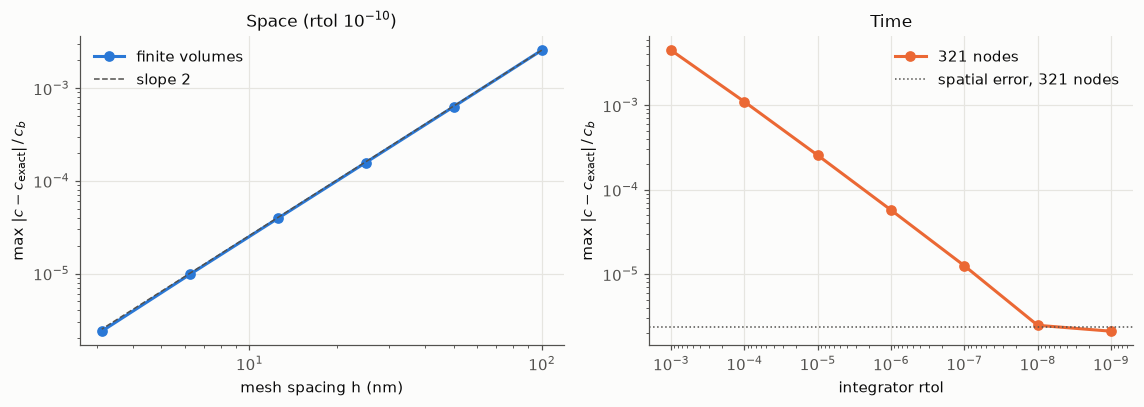

In [6]:
rtols = [1e-3, 1e-4, 1e-5, 1e-6, 1e-7, 1e-8, 1e-9]
timing = [max_rel_error(321, r) for r in rtols]
for r, (e, steps) in zip(rtols, timing):
    print(f"rtol {r:.0e}: max rel. error {e:.2e} in {steps:5d} steps")
print(f"spatial floor on 321 nodes: {space[-1]:.2e}")
assert timing[-1][0] < 1.5 * space[-1]                   # tight rtol reaches the spatial floor

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 3.8))
h = np.array([delta / (n - 1) for n in grids])
ax1.loglog(h * 1e9, space, "o-", color=BLUE, label="finite volumes")
ax1.loglog(h * 1e9, space[0] * (h / h[0]) ** 2, color=INK2, linewidth=1, linestyle="--", label=r"slope 2")
ax1.set(xlabel="mesh spacing h (nm)", ylabel=r"max $|c - c_{\rm exact}|\,/\,c_b$", title="Space (rtol $10^{-10}$)")
ax1.legend()
ax2.loglog(rtols, [e for e, _ in timing], "o-", color=ORANGE, label="321 nodes")
ax2.axhline(space[-1], color=INK2, linewidth=1, linestyle=":", label="spatial error, 321 nodes")
ax2.set(xlabel="integrator rtol", ylabel=r"max $|c - c_{\rm exact}|\,/\,c_b$", title="Time")
ax2.invert_xaxis()
ax2.legend()
fig.tight_layout()

The time error follows the tolerance down and levels off at the spatial error. Both error sources are therefore under control, and the solution can be trusted to the accuracy chosen.

**Limits.** The surface concentration from the solver (161 nodes, rtol $10^{-8}$) after a flux switched on at $t = 0$, against the semi-infinite short-time solution and the steady state:

t = 1e-4 tau: solver/semi-infinite = 0.9747;  t = 20 tau: solver/steady = 1.000000


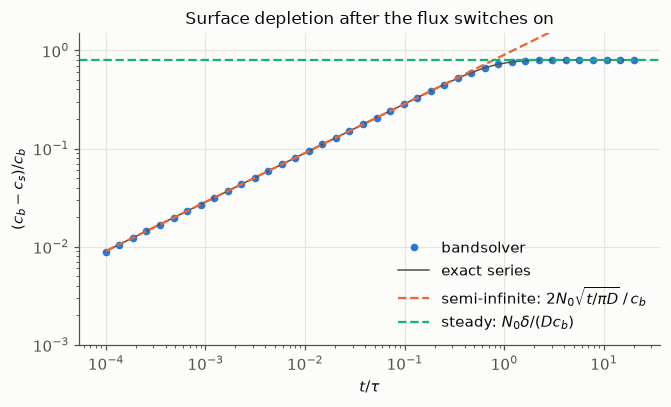

In [7]:
t_out = list(np.logspace(-4, 1.3, 40) * tau)
x, T, Y, _ = simulate(161, delta, N0, [0.0], t_out, rtol=1e-8)
drop = (c_b - Y[:, 0]) / c_b
short = 2 * N0 / D * np.sqrt(D * T / np.pi) / c_b
steady = N0 * delta / D / c_b

fig, ax = plt.subplots(figsize=(6.2, 3.8))
ax.loglog(T / tau, drop, "o", color=BLUE, markersize=4, label="bandsolver")
ax.loglog(T / tau, (c_b - c_exact(np.array([0.0]), T, delta, N0, [0.0])[:, 0]) / c_b, color=INK2,
          linewidth=1, label="exact series")
ax.loglog(T / tau, short, color=ORANGE, linestyle="--", linewidth=1.5, label=r"semi-infinite: $2N_0\sqrt{t/\pi D}\,/\,c_b$")
ax.axhline(steady, color=AQUA, linestyle="--", linewidth=1.5, label=r"steady: $N_0\delta/(D c_b)$")
ax.set(xlabel=r"$t/\tau$", ylabel=r"$(c_b - c_s)/c_b$", title="Surface depletion after the flux switches on", ylim=(1e-3, 1.5))
ax.legend(loc="lower right")
fig.tight_layout()
print(f"t = 1e-4 tau: solver/semi-infinite = {drop[0] / short[0]:.4f};  t = 20 tau: solver/steady = {drop[-1] / steady:.6f}")
assert abs(drop[-1] / steady - 1) < 1e-6

The solver follows the $\sqrt t$ law until the depletion front, of depth $\sim\!\sqrt{Dt}$, reaches the bulk side near $t \approx 0.3\,\tau$, then bends over to the steady value. At the earliest time shown the solver gives 97.5 % of the $\sqrt t$ value: there the depletion depth, $0.01\,\delta$, spans less than two cells of this mesh, and the gap closes with refinement, as section 4 showed.

## 5. The physics: what sets the surface-pH relaxation in GITT

A GITT protocol: three 10 s pulses, each followed by a 30 s rest. We compare two layer thicknesses at the same relative flux $N_0 = 0.8\,N_{\lim}$:
- $\delta = 1$ µm, the value used in the original study (a pore-scale layer): $\tau = 2$ ms;
- $\delta = 100$ µm, a diffusion layer on the scale of a separator: $\tau = 20$ s, comparable to the pulse and the rest.

delta =     1 um:  1824 steps, max rel. error in c_s 6.7e-13; surface pH just before pulses 2 and 3: 5.0000, 5.0000
delta =   100 um:  1573 steps, max rel. error in c_s 5.0e-05; surface pH just before pulses 2 and 3: 5.0051, 5.0052


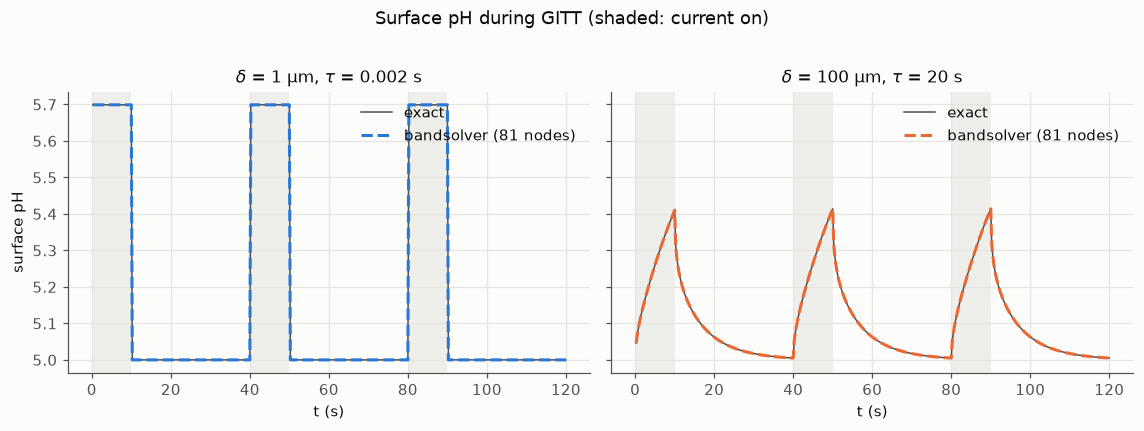

In [8]:
protocol = [0.0, 10.0, 40.0, 50.0, 80.0, 90.0]            # on, off, on, off, on, off (s)
t_out = list(np.linspace(0.25, 120.0, 480))
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8), sharey=True)
for ax, delta, color in zip(axes, (1e-6, 100e-6), (BLUE, ORANGE)):
    tau, N_lim = scales(delta)
    N0 = 0.8 * N_lim
    x, T, Y, stats = simulate(81, delta, N0, protocol, t_out, rtol=1e-6)
    exact_s = c_exact(np.array([0.0]), T, delta, N0, protocol)[:, 0]
    err = np.abs(Y[:, 0] - exact_s).max() / c_b
    for on, off in zip(protocol[::2], protocol[1::2]):
        ax.axvspan(on, off, color=GRID, alpha=0.6, linewidth=0)
    ax.plot(T, pH(exact_s), color=INK2, linewidth=1, label="exact")
    ax.plot(T, pH(Y[:, 0]), color=color, linestyle="--", label="bandsolver (81 nodes)")
    ax.set(xlabel="t (s)", title=fr"$\delta$ = {delta * 1e6:.0f} µm, $\tau$ = {tau:.3g} s")
    ax.legend(loc="upper right")
    before = [pH(Y[np.argmin(np.abs(T - (ts - 0.25))), 0]) for ts in protocol[2::2]]
    assert err < 2e-4
    print(f"delta = {delta * 1e6:5.0f} um: {stats['steps']:5d} steps, max rel. error in c_s {err:.1e}; "
          f"surface pH just before pulses 2 and 3: {before[0]:.4f}, {before[1]:.4f}")
axes[0].set_ylabel("surface pH")
fig.suptitle("Surface pH during GITT (shaded: current on)", y=1.02)
fig.tight_layout()

- **Thin layer** ($\tau \ll$ pulse): the surface pH jumps to its steady value at every switch and stays flat. The surface is in quasi-steady state with the current. A pore-scale model can treat the surface pH as an *algebraic* function of the current: $c_s = c_b - N\delta/D$.
- **Thick layer** ($\tau \sim$ pulse): the surface pH is still rising when the current stops (it reaches 5.41, short of the steady 5.70), then relaxes over roughly one $\tau$. With 30 s rests ($1.5\,\tau$) it is back to within 0.006 pH units of the bulk before the next pulse, so the three pulses look alike. With rests shorter than about $\tau$, each pulse would start from a shifted state, and an "equilibrium" voltage read at the end of a rest would still carry a pH-dependent offset. The rest needed for a clean GITT reading therefore scales with $\delta^2/D$.

The adaptive integrator spends its steps where they are needed: each switch restarts it with a small step that grows as the transient decays. The profiles for the thick layer show the depletion front moving in during a pulse and filling back during the rest:

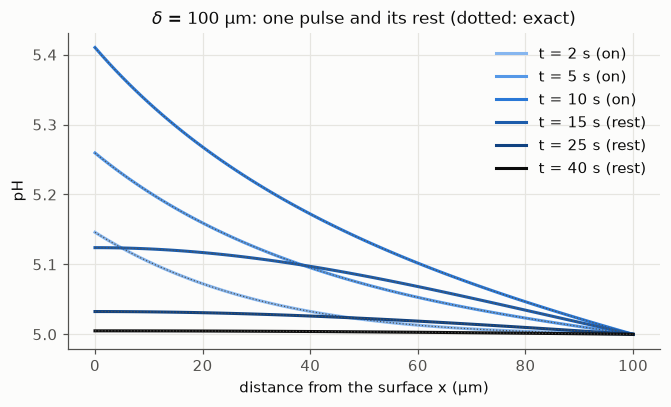

In [9]:
delta = 100e-6
tau, N_lim = scales(delta)
N0 = 0.8 * N_lim
snap = [2.0, 5.0, 10.0, 15.0, 25.0, 40.0]
x, T, Y, _ = simulate(81, delta, N0, protocol[:2], snap, rtol=1e-6)
fig, ax = plt.subplots(figsize=(6.2, 3.8))
for k, t in enumerate(T):
    state = "on" if t <= 10.0 else "rest"
    ax.plot(x * 1e6, pH(Y[k]), color=(RAMP + [INK])[k], label=f"t = {t:g} s ({state})")
    ax.plot(x * 1e6, pH(c_exact(x, t, delta, N0, protocol[:2])[0]), color=INK2, linewidth=0.8, linestyle=":")
ax.set(xlabel="distance from the surface x (µm)", ylabel="pH", title=r"$\delta$ = 100 µm: one pulse and its rest (dotted: exact)")
ax.legend()
fig.tight_layout()

## 6. Summary and limits

| check | result |
|---|---|
| spatial convergence | second order against the exact series, including the flux boundary |
| temporal convergence | error follows rtol down to the spatial floor |
| short-time limit | $\sqrt t$ law of the semi-infinite layer |
| long-time limit | steady linear profile, $c_s = c_b - N_0\delta/D$ |
| pulse trains | segment-wise integration with restarts at each switch; matches the superposed exact solution |

**What this model leaves out.** It has one species and no buffering, so the limiting flux is orders of magnitude below battery currents. In a real electrolyte, complexation and precipitation equilibria supply or absorb protons and pin the surface pH much closer to the bulk. Migration also matters if the supporting electrolyte is not in excess. Those effects turn this linear problem into a coupled, nonlinear one (more unknowns per node, the same block-tridiagonal structure), the kind of system notebooks [2](02_binary_electrolyte.ipynb) and [3](03_porous_electrode.ipynb) solve.

**Provenance.** The problem setup (a 1 µm layer, $D = 5\times10^{-6}$ cm²/s, bulk pH 5, switched surface flux) follows boundary-layer codes written with the original BAND routine during the author's PhD work on GITT pH effects. The code here is new.